Text(0.5, 1.0, 'GMM slice, dim=100, K=100')

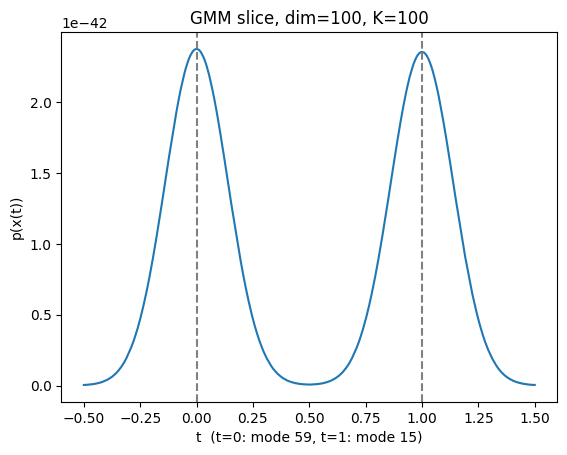

In [6]:
import torch, matplotlib.pyplot as plt
from adjoint_samplers.utils.dist_utils import GMM

dim, K = 100, 100
gmm = GMM(dim=dim, K=K, seed=0)          # same target as target_seed=0

# line through the two heaviest modes: x(t) = μ_i + t (μ_j - μ_i)
i, j = gmm.weights.argsort(descending=True)[:2]
t = torch.linspace(-0.5, 1.5, 1000)
x = gmm.means[i] + t[:, None] * (gmm.means[j] - gmm.means[i])

with torch.no_grad():
    density = gmm.log_prob(x).exp()

plt.plot(t, density)
plt.axvline(0, ls="--", c="gray"); plt.axvline(1, ls="--", c="gray")
plt.xlabel(f"t  (t=0: mode {i.item()}, t=1: mode {j.item()})")
plt.ylabel("p(x(t))")
plt.title(f"GMM slice, dim={dim}, K={K}")
